# IND320 project work, part 2

Viktor, NMBU, autumn 2026.

- GitHub repository: https://github.com/viktorbgulbrandsen/ind320-viktorbgulbrandsen
- Streamlit app: https://ind320-proj2-viktorbgulbrandsen.streamlit.app/
- Video: https://drive.google.com/file/d/1OSyvvVfai_WMk8zYPrnPDuh50rHyGTgq/view?usp=sharing


# API

I have opted to restructure the repo into projectn/ at root level. Although this might create a bit of hassle in some of the tasks, I think it will yield easier overview of what belongs to which part, and also some practice in modularity.

The first step we take is not using the CSV as previously downloaded but rather directly pulling from the Magasinstatistikk API.


In [110]:
import requests
import pandas as pd
import plotly.express as px
import plotly.io as pio

# plots as png, so they show up in the pdf export and not only in the browser
pio.renderers.default = "png"


In [111]:
api_url = "https://biapi.nve.no/magasinstatistikk/api/Magasinstatistikk/HentOffentligData"

# just test the hit with a plain GET.

response = requests.get(api_url)
response.raise_for_status()
print(type(response))

<class 'requests.models.Response'>


In [112]:
#response OK, traverse with Pandas
df = pd.DataFrame(response.json())
print(df.shape)
df.head()

(14922, 11)


,dato_Id,omrType,omrnr,iso_aar,iso_uke,fyllingsgrad,kapasitet_TWh,fylling_TWh,neste_Publiseringsdato,fyllingsgrad_forrige_uke,endring_fyllingsgrad
0,1995-09-03,EL,4,1995,35,0.944721,21.079208,19.913979,0001-01-01T00:00:00,0.936888,0.007833
1,2020-11-15,EL,1,2020,46,0.974361,6.003264,5.849344,2020-11-25T13:00:00,0.997406,-0.023046
2,2011-08-28,EL,4,2011,34,0.786499,21.079208,16.578772,0001-01-01T00:00:00,0.787193,-0.000694
3,1998-07-05,EL,3,1998,27,0.793969,8.920932,7.082947,0001-01-01T00:00:00,0.733812,0.060157
4,2011-03-27,EL,4,2011,12,0.300820,21.079208,6.341054,0001-01-01T00:00:00,0.311122,-0.010301


In [113]:
# look at datatypes and the dato_Id
df.dtypes
df["dato_Id"].iloc[0], type(df["dato_Id"].iloc[0])


('1995-09-03', str)

In [114]:
#df["dato_Id"].dt.to_period("M")
#this line does not work because  as we see above, we are given dato_Id as str, so we need to convert

#convert
df["dato_Id"] = pd.to_datetime(df["dato_Id"])
df["dato_Id"].dt.to_period("M")

0        1995-09
1        2020-11
2        2011-08
3        1998-07
4        2011-03
          ...   
14917    2026-10
14918    2026-10
14919    2026-10
14920    2026-10
14921    2026-10
Name: dato_Id, Length: 14922, dtype: period[M]

In [115]:
#rows come in random order, as in part 1. sort by date, fix index
df = df.sort_values("dato_Id")
df = df.reset_index(drop=True)
df.head()

,dato_Id,omrType,omrnr,iso_aar,iso_uke,fyllingsgrad,kapasitet_TWh,fylling_TWh,neste_Publiseringsdato,fyllingsgrad_forrige_uke,endring_fyllingsgrad
0,1995-01-08,EL,5,1995,1,0.616448,17.390587,10.720388,0001-01-01T00:00:00,0.614288,0.002160
1,1995-01-08,VASS,2,1995,1,0.608856,23.237715,14.148431,0001-01-01T00:00:00,0.744693,-0.135837
2,1995-01-08,VASS,3,1995,1,0.566906,28.155403,15.961480,0001-01-01T00:00:00,0.661432,-0.094525
3,1995-01-08,VASS,1,1995,1,0.635440,36.044464,22.904102,0001-01-01T00:00:00,0.756482,-0.121041
4,1995-01-08,NO,0,1995,1,0.607988,87.437580,53.161003,0001-01-01T00:00:00,0.752631,-0.144643


In [116]:
# let us convert the names again
columns = {
    "dato_Id": "date",
    "omrType": "area_type",
    "omrnr": "area_no",
    "iso_aar": "iso_year",
    "iso_uke": "iso_week",
    "fyllingsgrad": "fill_level",
    "kapasitet_TWh": "capacity_TWh",
    "fylling_TWh": "fill_TWh",
    "fyllingsgrad_forrige_uke": "fill_level_prev_week",
    "endring_fyllingsgrad": "fill_level_change",
}

#drop publiseringsdato as in part 1, rename
df = df.drop(columns="neste_Publiseringsdato")
df = df.rename(columns=columns)
df.head()


,date,area_type,area_no,iso_year,iso_week,fill_level,capacity_TWh,fill_TWh,fill_level_prev_week,fill_level_change
0,1995-01-08,EL,5,1995,1,0.616448,17.390587,10.720388,0.614288,0.002160
1,1995-01-08,VASS,2,1995,1,0.608856,23.237715,14.148431,0.744693,-0.135837
2,1995-01-08,VASS,3,1995,1,0.566906,28.155403,15.961480,0.661432,-0.094525
3,1995-01-08,VASS,1,1995,1,0.635440,36.044464,22.904102,0.756482,-0.121041
4,1995-01-08,NO,0,1995,1,0.607988,87.437580,53.161003,0.752631,-0.144643


In [117]:
# the API has a clean list of areas.
areas_url = "https://biapi.nve.no/magasinstatistikk/api/Magasinstatistikk/HentOmråder"
areas = requests.get(areas_url).json()
areas

[{'land': [{'navn': 'Norge',
    'navn_langt': 'Norge',
    'beskrivelse': 'Hele landet',
    'omrType': 'NO',
    'omrnr': 0}],
  'elspot': [{'navn': 'NO 1',
    'navn_langt': 'Elspotområde 1',
    'beskrivelse': 'Sørøst-Norge. Omfatter østlige del av Østlandet fra Buskerud og nordover (bortsett fra den del av Innlandet som ligger vest og nord for Vågåmo).',
    'omrType': 'EL',
    'omrnr': 1},
   {'navn': 'NO 2',
    'navn_langt': 'Elspotområde 2',
    'beskrivelse': 'Sørvest-Norge. Omfatter mesteparten av Vestfold, Telemark, Agder, Rogaland og sørlige del av Vestland.',
    'omrType': 'EL',
    'omrnr': 2},
   {'navn': 'NO 3',
    'navn_langt': 'Elspotområde 3',
    'beskrivelse': 'Midt-Norge. Omfatter nordre og vestlige del av Vestland, den del av Innlandet som ligger vest og nord for Vågåmo, Møre og Romsdal og Trøndelag til Tunnsjødal.',
    'omrType': 'EL',
    'omrnr': 3},
   {'navn': 'NO 4',
    'navn_langt': 'Elspotområde 4',
    'beskrivelse': 'Nord-Norge. Omfatter resten av

In [118]:
# let us make a table by area, using that dict seen above

area_table = pd.DataFrame()
for group in areas[0]:
    area_table = pd.concat([area_table, pd.DataFrame(areas[0][group])])

area_table = area_table.reset_index(drop=True)
area_table[["omrType", "omrnr", "navn", "beskrivelse"]]


,omrType,omrnr,navn,beskrivelse
0,NO,0,Norge,Hele landet
1,EL,1,NO 1,Sørøst-Norge. Omfatter østlige del av Østlande...
2,EL,2,NO 2,Sørvest-Norge. Omfatter mesteparten av Vestfol...
3,EL,3,NO 3,Midt-Norge. Omfatter nordre og vestlige del av...
4,EL,4,NO 4,Nord-Norge. Omfatter resten av Trøndelag og No...
5,EL,5,NO 5,Vest-Norge. Omfatter midtre del av Vestland op...
6,VASS,1,VASS1,"Sørøst-Norge. Østlandet, Agder og deler av Rog..."
7,VASS,2,VASS2,Vest-Norge. Resten av Rogaland og Vestland.
8,VASS,3,VASS3,"Midt-Norge. Møre og Romsdal, Trøndelag og sørl..."
9,VASS,4,VASS4,Nord-Norge. Resten av Nordland og nordover.


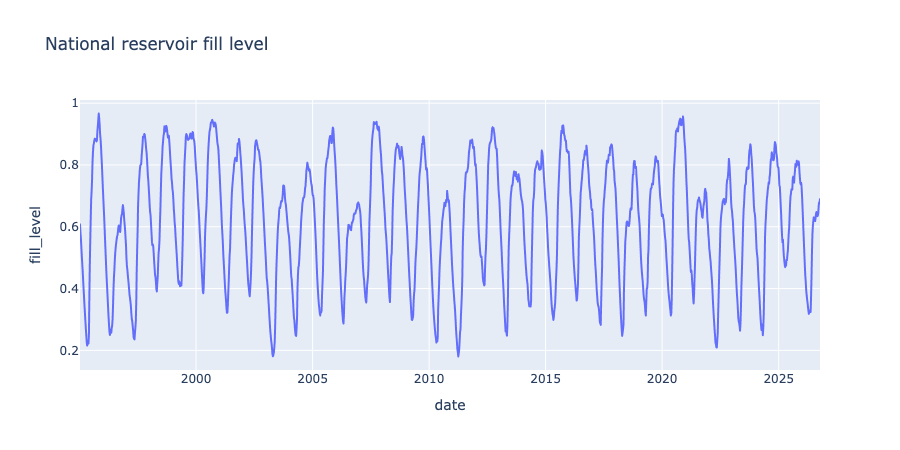

In [119]:
#national total over date,  same as national() in part 1
series = df[df["area_type"] == "NO"]
series = series.set_index("date")
series = series[["fill_level", "capacity_TWh", "fill_TWh", "fill_level_prev_week", "fill_level_change"]]
series.head()
#makeplot
fig = px.line(series, y="fill_level", title="National reservoir fill level")
fig.show()


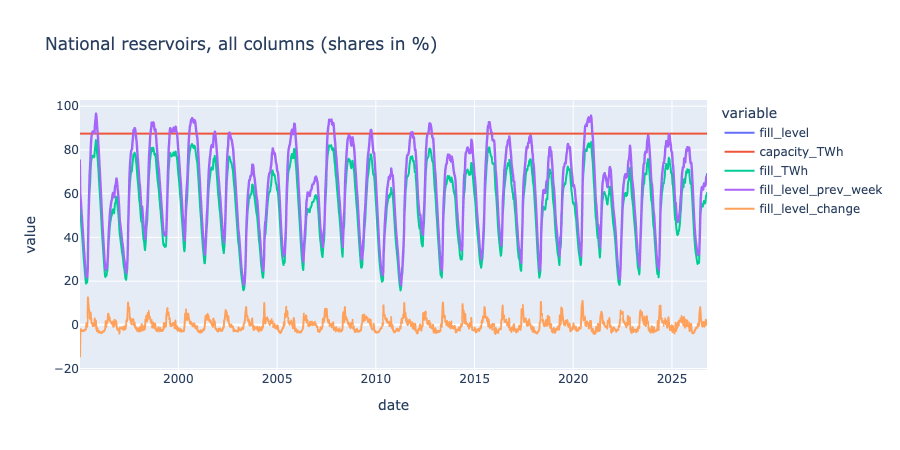

In [93]:
#all columns in one plot
#to normalize the scale I place the shares in percent, so they fit on an axis with Twh

copy = series.copy()
for column in ["fill_level", "fill_level_prev_week", "fill_level_change"]:
    copy[column] = copy[column] * 100

fig = px.line(copy, title="National reservoirs, all columns (shares in %)")
fig.show()

# ENTSO-E


In [94]:
from dotenv import load_dotenv
import os
#import modules to read .env file in root

load_dotenv("../.env") #path
token = os.environ["ENTSOE_API_KEY"]


In [95]:
entsoe_url = "https://web-api.tp.entsoe.eu/api"
#requests.get(entsoe_url).text 
#add security token
requests.get(entsoe_url, params={"securityToken": token}).text

'<?xml version="1.0" encoding="UTF-8"?>\n<Acknowledgement_MarketDocument\n\txmlns="urn:iec62325.351:tc57wg16:451-1:acknowledgementdocument:7:0">\n\t<mRID>7e7335a1-acfc-4</mRID>\n\t<createdDateTime>2026-10-20T15:38:36Z</createdDateTime>\n\t<sender_MarketParticipant.mRID codingScheme="A01">10X1001A1001A450</sender_MarketParticipant.mRID>\n\t<sender_MarketParticipant.marketRole.type>A32</sender_MarketParticipant.marketRole.type>\n\t<receiver_MarketParticipant.mRID codingScheme="A01">10X1001A1001A450</receiver_MarketParticipant.mRID>\n\t<receiver_MarketParticipant.marketRole.type>A39</receiver_MarketParticipant.marketRole.type>\n\t<received_MarketDocument.createdDateTime>2026-10-20T15:38:36Z</received_MarketDocument.createdDateTime>\n\t<Reason>\n\t\t<code>999</code>\n\t\t<text>The combination of [] is not valid, or the requested data is not allowed to be fetched via this service.</text>\n\t</Reason>\n</Acknowledgement_MarketDocument>\n'

In [96]:
params = {
    "securityToken": token,
    "documentType": "A11",
    "in_Domain": "10Y1001A1001A46L",
    "out_Domain": "10YNO-1--------2",
    "periodStart": "202510010000",
    "periodEnd": "202510020000",
}
response = requests.get(entsoe_url, params=params)
print(response.text[:1500])

<?xml version="1.0" encoding="utf-8"?>
<Publication_MarketDocument xmlns="urn:iec62325.351:tc57wg16:451-3:publicationdocument:7:0">
  <mRID>ac69d34df86749c2a72e47a187e445b6</mRID>
  <revisionNumber>1</revisionNumber>
  <type>A11</type>
  <sender_MarketParticipant.mRID codingScheme="A01">10X1001A1001A450</sender_MarketParticipant.mRID>
  <sender_MarketParticipant.marketRole.type>A32</sender_MarketParticipant.marketRole.type>
  <receiver_MarketParticipant.mRID codingScheme="A01">10X1001A1001A450</receiver_MarketParticipant.mRID>
  <receiver_MarketParticipant.marketRole.type>A33</receiver_MarketParticipant.marketRole.type>
  <createdDateTime>2026-10-20T15:38:43Z</createdDateTime>
  <period.timeInterval>
    <start>2025-10-01T00:00Z</start>
    <end>2025-10-02T00:00Z</end>
  </period.timeInterval>
    <TimeSeries>
      <mRID>1</mRID>
      <businessType>A66</businessType>
      <in_Domain.mRID codingScheme="A01">10Y1001A1001A46L</in_Domain.mRID>
      <out_Domain.mRID codingScheme="A01">1

In [97]:
#from the print we see that the response is XML with one TimeSeries for the flow from NO1 to SE3, and inside it a Period with a start time, a resolution of 15 minutes, and a list of Points.
#to get this into a table I pull out every Point with xml.etree.
import xml.etree.ElementTree as ET

root = ET.fromstring(response.text)
ns = {"ns": "urn:iec62325.351:tc57wg16:451-3:publicationdocument:7:0"}

rows = []
for point in root.iter("{urn:iec62325.351:tc57wg16:451-3:publicationdocument:7:0}Point"):
    position = int(point.find("ns:position", ns).text)
    quantity = float(point.find("ns:quantity", ns).text)
    rows.append({"position": position, "quantity": quantity})

points = pd.DataFrame(rows)
print(points.shape)
points.head(10)


(41, 2)


,position,quantity
0,1,0.00
1,16,147.18
2,17,317.47
3,18,363.88
4,19,466.69
5,20,505.23
6,21,635.96
7,22,654.47
8,23,636.01
9,24,659.67


In [98]:
start = pd.Timestamp("2025-10-01T00:00Z")

points = points.set_index("position")
points = points.reindex(range(1, 97))
points["quantity"] = points["quantity"].ffill()

points["time"] = start + pd.to_timedelta((points.index - 1) * 15, unit="min")
points = points.set_index("time")
print(points.shape)
points.head(20)

(96, 1)


,quantity
time,
2025-10-01 00:00:00+00:00,0.00
2025-10-01 00:15:00+00:00,0.00
2025-10-01 00:30:00+00:00,0.00
2025-10-01 00:45:00+00:00,0.00
2025-10-01 01:00:00+00:00,0.00
2025-10-01 01:15:00+00:00,0.00
2025-10-01 01:30:00+00:00,0.00
2025-10-01 01:45:00+00:00,0.00
2025-10-01 02:00:00+00:00,0.00


In [99]:
#i refactor out the parsing of the XML into a utils/entsoe.py, as a function fetch_flows
#in this way, I can collect flows from any border and both directions with one call, and the app can import the same function later
from utils.entsoe import fetch_flows

#same day as above, should give 96 rows and the same numbers
test = fetch_flows("10YNO-1--------2", "10Y1001A1001A46L", "202510010000", "202510020000")
print(test.shape)
test.head()

(96, 3)


,quantity,out_area,in_area
time,,,
2025-10-01 00:00:00+00:00,0.0,10YNO-1--------2,10Y1001A1001A46L
2025-10-01 00:15:00+00:00,0.0,10YNO-1--------2,10Y1001A1001A46L
2025-10-01 00:30:00+00:00,0.0,10YNO-1--------2,10Y1001A1001A46L
2025-10-01 00:45:00+00:00,0.0,10YNO-1--------2,10Y1001A1001A46L
2025-10-01 01:00:00+00:00,0.0,10YNO-1--------2,10Y1001A1001A46L


In [100]:
# norway has nine connections abroad. codes from the API reference
areas = {
    "NO1": "10YNO-1--------2", "NO2": "10YNO-2--------T",
    "NO3": "10YNO-3--------J", "NO4": "10YNO-4--------9",
    "SE1": "10Y1001A1001A44P", "SE2": "10Y1001A1001A45N", "SE3": "10Y1001A1001A46L",
    "FI": "10YFI-1--------U", "DK1": "10YDK-1--------W", "NL": "10YNL----------L",
    "DE": "10Y1001A1001A82H", "GB": "10YGB----------A",
}
connections = [
    ("NO1", "SE3"), ("NO3", "SE2"), ("NO4", "SE1"), ("NO4", "SE2"), ("NO4", "FI"),
    ("NO2", "DK1"), ("NO2", "NL"), ("NO2", "DE"), ("NO2", "GB"),
]


In [101]:
# max one year per request so two windows
windows = [("202410200000", "202510200000"), ("202510200000", "202610200000")]

# every connection both ways. export is out of norway
frames = []
for norway, abroad in connections:
    for start, end in windows:
        out = fetch_flows(areas[norway], areas[abroad], start, end)
        out["connection"] = f"{norway}-{abroad}"
        out["direction"] = "export"
        back = fetch_flows(areas[abroad], areas[norway], start, end)
        back["connection"] = f"{norway}-{abroad}"
        back["direction"] = "import"
        frames.append(out)
        frames.append(back)

# one table. cassandra wants naive times
flows = pd.concat(frames)
flows = flows.reset_index()
flows["time"] = flows["time"].dt.tz_convert(None)
print(flows.shape)
flows.head()


(1261440, 6)


,time,quantity,out_area,in_area,connection,direction
0,2024-10-20 00:00:00,0.0,10YNO-1--------2,10Y1001A1001A46L,NO1-SE3,export
1,2024-10-20 00:15:00,0.0,10YNO-1--------2,10Y1001A1001A46L,NO1-SE3,export
2,2024-10-20 00:30:00,0.0,10YNO-1--------2,10Y1001A1001A46L,NO1-SE3,export
3,2024-10-20 00:45:00,0.0,10YNO-1--------2,10Y1001A1001A46L,NO1-SE3,export
4,2024-10-20 01:00:00,0.0,10YNO-1--------2,10Y1001A1001A46L,NO1-SE3,export


# Cassandra and Spark


In [102]:
# keyspace and table through the plain driver
from cassandra.cluster import Cluster

cluster = Cluster(["127.0.0.1"])
session = cluster.connect()
session.execute("CREATE KEYSPACE IF NOT EXISTS ind320 WITH replication = {'class': 'SimpleStrategy', 'replication_factor': 1}")
session.execute("""
    CREATE TABLE IF NOT EXISTS ind320.flows (
        connection text, direction text, time timestamp,
        quantity double, out_area text, in_area text,
        PRIMARY KEY ((connection, direction), time)
    )
""")


In [103]:
# spark needs java 17. config as in the book
import sys
os.environ["JAVA_HOME"] = "/opt/homebrew/opt/openjdk@17"
# the spark workers must run the same python as this kernel, not the system one
os.environ["PYSPARK_PYTHON"] = sys.executable
from pyspark.sql import SparkSession

spark = (
    SparkSession.builder.appName("ind320")
    .config("spark.jars.packages", "com.datastax.spark:spark-cassandra-connector_2.12:3.5.1")
    .config("spark.cassandra.connection.host", "127.0.0.1")
    .getOrCreate()
)

# pandas to spark to cassandra
spark_flows = spark.createDataFrame(flows)
spark_flows.write.format("org.apache.spark.sql.cassandra").options(table="flows", keyspace="ind320").mode("append").save()


26/10/20 17:44:39 WARN TaskSetManager: Stage 10 contains a task of very large size (6411 KiB). The maximum recommended task size is 1000 KiB.


In [104]:
# read back and keep the columns we need
stored = spark.read.format("org.apache.spark.sql.cassandra").options(table="flows", keyspace="ind320").load()
stored = stored.select("connection", "direction", "time", "quantity")
print(stored.count())
flows_pd = stored.toPandas()
flows_pd.head()


1261296


,connection,direction,time,quantity
0,NO1-SE3,import,2024-10-20 00:00:00,1002.2950
1,NO1-SE3,import,2024-10-20 00:15:00,1064.2175
2,NO1-SE3,import,2024-10-20 00:30:00,1084.2900
3,NO1-SE3,import,2024-10-20 00:45:00,1084.1575
4,NO1-SE3,import,2024-10-20 01:00:00,931.2125


# Plots


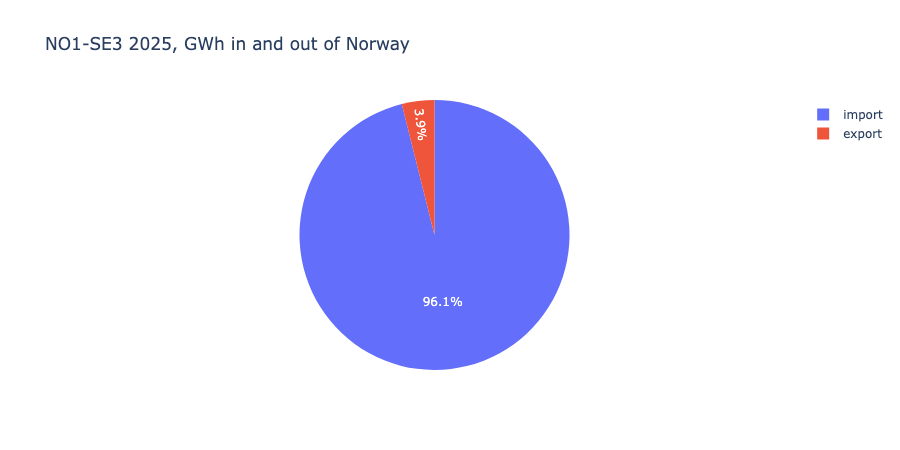

In [105]:
# pie chart for one year of one connection
year = 2025
connection = "NO1-SE3"

# the data is MW, so I take the hourly mean and sum it to get MWh. then divide to GWh
one = flows_pd[(flows_pd["connection"] == connection) & (flows_pd["time"].dt.year == year)]
hourly = one.set_index("time").groupby("direction")["quantity"].resample("1h").mean()
totals = hourly.groupby("direction").sum() / 1000

fig = px.pie(values=totals.values, names=totals.index, title=f"{connection} {year}, GWh in and out of Norway")
fig.show()


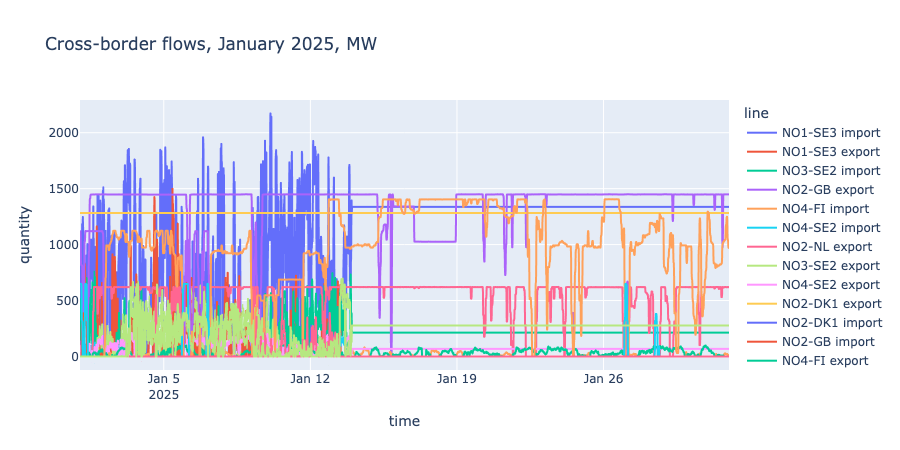

In [106]:
# line plot for january, one line per connection and direction
month = flows_pd[(flows_pd["time"].dt.year == year) & (flows_pd["time"].dt.month == 1)]
month = month.assign(line=month["connection"] + " " + month["direction"])

fig = px.line(month, x="time", y="quantity", color="line", title=f"Cross-border flows, January {year}, MW")
fig.show()


# MongoDB


In [107]:
# now the spark result goes into mongodb, which is what the app will read from
from pymongo import MongoClient

client = MongoClient(os.environ["MONGO_URI"])
collection = client["ind320"]["flows"]

# I drop the collection first, so running the notebook again does not double the rows
collection.drop()

# the free tier chokes on one giant insert, so 5000 rows at a time
records = flows_pd.to_dict("records")
for i in range(0, len(records), 5000):
    collection.insert_many(records[i:i + 5000])

print(collection.count_documents({}))


1261296


In [108]:
# print the app code here as well, as suggested in the peer review
!cat streamlit_app.py views/*.py utils/*.py


import streamlit as st

#wide layout for every page, set once before the navigation
st.set_page_config(layout="wide")

pages = [
    st.Page("views/1_home.py", title="Home"),
    st.Page("views/2_table.py", title="Data table"),
    st.Page("views/3_plot.py", title="Plot"),
    st.Page("views/4_flows.py", title="Cross-border flows"),
    st.Page("views/5_latest_week.py", title="Latest week"),
]

menu = st.navigation(pages)
menu.run()
import streamlit as st

st.title("Norwegian reservoir levels and cross-border flows")

st.write("This app looks at how full the Norwegian hydropower reservoirs are, week by week from 1995 to 2026.")
st.write("The reservoir data is fetched live from the NVE Magasinstatistikk API.")
st.write("The page on cross-border flows shows electricity flows between Norway and its neighbours.")
st.write("The flows go ENTSO-E API → Cassandra via Spark → MongoDB, which the app reads.")
st.write("Use the menu on the left to switch between pages.")
#import pandas, streamlit


# Log

**19 october**

One of the first problems I encountered was that Spark needs an older Python, while I previously deployed and developed with Python 3.14. I asked Claude Fable 5.1 through Claude Code whether Spark really needs 3.12, which answered:

> Not from memory. Let me check what actually ran on 16.10 and what the package itself declares.

It then ran a two-row Spark job on 3.14 and came back with:

> `pyspark` 3.5.9 declares Python `>=3.8` with no upper bound, so nothing warns you. On your Python 3.14, it crashes on the very first 2-row DataFrame: `PicklingError … RecursionError: Stack overflow`. On 16.10 the Cassandra test ran on 3.12, and worked.

When I worried about redeploying the app with a new Python, it answered:

> Maybe not. The app never runs Spark. Spark and Cassandra are notebook-only; the app reads from MongoDB and the NVE API. So streamlit.app can stay on 3.14 as deployed, and only your local env drops to 3.12 for the notebook.

I asked it to set the project to Python 3.12 without forcing it on the deployment, and it answered with:

> `requires-python >=3.12`, `.python-version` 3.12, `requests` + `pymongo` as app deps, `pyspark` + `cassandra-driver` + `setuptools` in dev. Env is now Python 3.12.14 and a 2-row Spark DataFrame runs inside it.

I hit the API, and everything looks nice. Because it is in an API, the standard payload is JSON which is essentially a list of dicts. Pandas can turn this into a table, however `dato_Id` comes as text. I therefore convert with `pd.to_datetime`. The API also nicely exposes a list of areas, which I turn into a table.

**20 october**

ENTSO-E has no swagger, so a bare hit only exposes authentication failed. While authentication is OK passing `params = {"securityToken": token}`, the return is pure XML. So I had to ask Claude a bit about how to most nicely parse this. Because there was so much clutter, I chose to refactor this into `utils/entsoe.py`.

Cassandra runs in Docker through colima and Spark talks to it with the connector from the book. I make the keyspace and the table with the plain Cassandra driver first. The key is connection and direction and the rows are sorted by time inside each key, so one connection in one direction is one partition. Then the pandas table goes through Spark into Cassandra and I read it back with Spark keeping only the four columns the plots and the app need.

The pie is one year of one connection. The data is MW so I take the hourly mean and sum to get MWh and show it in GWh. The line plot is January with one line per connection and direction. The Spark result goes into MongoDB which is what the app reads. I drop the collection first so a rerun does not double the rows. The app code is printed at the end of the notebook as the peer review suggested.

**20 october, the app**

The app got its own `utils/` with three files. `nve.py` is the notebook cells for the reservoir data as two functions, `entsoe.py` is the XML parsing from before, and `mongo.py` is the client and the two queries the app needs. The pages import from there, so the notebook and the app share code instead of copying it.

The NVE endpoint has no date parameters, so the whole history is fetched once and cached, and the slider from page three now slices which rows are kept. The radio for EL, NO and VASS picks the area type and the table and the plot show one line per area number of that type. What was on page four moved to page five.

Page four is the MongoDB page. Two columns: on the left a radio for the connection and a selectbox for the year with the pie chart, on the right pills for the months with the line plot, and an expander about the data below. The client is cached with `st.cache_resource` and the queries with `st.cache_data(ttl=600)` as in the book. The URI comes from `.env` locally and from the Streamlit secrets online.

Running the notebook from the terminal instead of the editor, Spark failed because its workers started the system Python 3.14 while the kernel was 3.12. One line fixed it: `PYSPARK_PYTHON` set to the kernel's own Python.


# AI Log

**20 october**

Plotting all columns together, the shares lay flat at the bottom because the TWh columns go up to about 87. Claude suggested the same fix as in part 1, a second y-axis for the TWh columns. I asked if I could just put the shares in percent instead, so they run from 0 to 100 and fit the same axis as the TWh columns. Claude answered: "Yes: shares times 100 go from 0 to 100, the TWh columns go up to 87, so they fit one axis. Simpler than a second axis. The cost: one axis with two units on it, percent and TWh."

I asked Claude how to get the points out of an XML response like this. It suggested `xml.etree` from the standard library, and pointed out that the namespace in the root tag has to be repeated on every tag you look up: "Plain xml.etree, and the namespace has to be given on every tag."

Claude caught that the function assumed 15-minute steps; before October 2025 the data is hourly, so `fetch_flows` now reads the resolution from the XML.

For the ENTSO-E part I used Claude for three specific things. First how to parse the XML response, where it pointed me to `xml.etree` and the namespace trick. Second to double check the area codes for the nine Norwegian connections against the API reference. Third the units for the pie chart: the data is in MW, so to get energy I take the hourly mean and sum it to MWh, which makes the 15 minute rows and the hourly rows count the same.

For Cassandra I asked Claude what a sensible primary key would be for this table. It suggested connection and direction as the partition key with time as the clustering column, so that a query for one connection in one direction reads one partition in time order. I also asked why the times had to be made naive before writing and the answer was that the Cassandra connector does not take timezone aware pandas timestamps.

For MongoDB I asked Claude how to avoid duplicate rows when the notebook is run again. It suggested dropping the collection before the insert since the notebook is the only writer. The `!cat` of the app files at the end was a suggestion from the peer review of part 1.

For the app I used Claude for a few specific things while I wrote the pages on the part 1 pattern.

I asked: "how do i keep one mongodb client for the whole app, i dont want to reconnect on every rerun". It answered: "Good question — this is exactly what `st.cache_resource` is for. Streamlit reruns your script top to bottom on every interaction, so without caching you'd open a new connection each time. Here's the pattern:

- `@st.cache_resource` on the function that creates the `MongoClient` — this keeps a single shared connection alive for the whole process.
- `@st.cache_data(ttl=600)` on the functions that run queries — this caches the returned DataFrame and refreshes it every 10 minutes.

This is the same split the course book uses in its MongoDB chapter."

I asked: "the deployed app has no .env, how do i get the uri there". It answered: "On Streamlit Community Cloud you add secrets through the app's **Settings → Secrets** panel, and they become available as `st.secrets`. A clean way to support both environments is:

```python
uri = os.environ.get("MONGO_URI")
if uri is None:
    uri = st.secrets["mongo"]["uri"]
```

Locally your `.env` is loaded first, and online the secrets take over — the same code works in both places without any changes."

I asked: "the nve endpoint has no date parameters, what does download interval even mean then". It answered: "You're right — the `HentOffentligData` endpoint returns the full history and has no date filters. In that case the 'download' is always everything, and the interval can only be applied afterwards. I'd suggest:

1. Fetch the full history once and wrap it in `st.cache_data` so it's not refetched on every rerun.
2. Let the slider slice the cached DataFrame by month.
3. Add a short comment explaining this, so a reader doesn't go looking for a date parameter that doesn't exist.

This satisfies the task's intent (the slider controls which data you work with) while being honest about what the API supports."

I asked: "st.pills, how do i get several months at once". It answered: "`st.pills` supports multi-selection via the `selection_mode` argument:

```python
picked = st.pills("Months", MONTHS, selection_mode="multi", default=["Jan"])
```

It returns a list of the selected labels. To convert them back to month numbers for filtering, you can use `MONTHS.index(name) + 1` for each picked name."

When the notebook was run from the terminal, Spark crashed with a Python version mismatch. I asked why it worked in the editor but not there. It answered: "This is a classic PySpark gotcha. The driver runs in your kernel's Python (3.12), but Spark launches its worker processes as a *separate* Python, which it finds via `PATH`. In the editor your venv was first on `PATH`; from the terminal it picked up the system Python 3.14, hence the mismatch. The fix is to pin the workers to the same interpreter before creating the session:

```python
import sys
os.environ["PYSPARK_PYTHON"] = sys.executable
```

Now driver and workers always agree, regardless of how the notebook is launched."

Three choices came from Claude and I kept them: the slider starts on the last five years since the first month gives only four points per area, the plot page lost the "all columns" option since the radio gives one column per plot, and the latest week page moved to page five as the task suggests.
